# 词元嵌入

在上一部分，我们用**循环神经网络**（RNN）第一次让模型读懂了莎士比亚。但是 RNN 存在两个先天缺陷：

* **记忆有限**：所有历史信息都要压缩进一个固定长度的隐状态。信息越塞越多，早期的内容很快就被挤出去了；
* **无法并行**：必须逐个词元顺序处理，前一个没算完，后一个就无法开始。面对海量文本，训练速度成为难以逾越的瓶颈。

2017年，Google 的研究团队发表了著名论文《Attention Is All You Need》，提出了全新的 Transformer 架构：彻底抛弃循环结构，完全依靠**注意力机制**（Attention Mechanism）处理词元序列。基于这一架构诞生的**生成式预训练**（Generative Pre-trained Transformer，GPT），开启了大语言模型时代。

---

从这一部分开始，我们将一步一个脚印，搭建一个真正的 GPT 模型：

* **编码器**：词元嵌入、位置嵌入，把文字转换成携带信息的向量；
* **自注意力机制**：因果、加权、多头，让词元之间互相关注，理解上下文；
* **预训练**：残差连接、归一化、随机失活，把模型堆深、堆大、训练好；
* **推理**：采样策略、停止条件、键值缓存、批量推理，控制模型生成、提高生成效率；
* **微调**：监督微调、偏好优化，让模型从预训练的“接话”模式，学会“对话”模式。

本章我们先走出第一步：搭建一个最基本的框架，并通过**词元嵌入**（Token Embedding）接入数据集。

In [1]:
from pathlib import Path

import requests

from src.core import *

``💡 通过引用 src.core，我们可以直接使用之前章节创建起来的模型训练框架。``

In [2]:
np.random.seed(42)

## 数据集

### 字符编码数据集

GPT 的数据集和 RNN 的数据集完全一样，不需要任何修改：

* **vocab**（词表）：按字符分词；
* **tokens**（词元表）：将全部文本转换为**索引编码**序列；
* **x**（特征值）：从文本中截取的一段词元序列 `tokens[i: i + context_size]`；
* **y**（标签值）：特征值词元序列整体后移一位 `tokens[i + 1: i + context_size + 1]`。

也就是说，每个样本包含 `context_size` 个预测任务：用第 1 个词元预测第 2 个词元，用前 2 个词元预测第 3 个词元，直到用前 `context_size` 个词元预测第 `context_size + 1` 个词元。

这种根据已有内容预测下一个词元的训练方式，称为**自回归**（Autoregressive）训练，也是 GPT 的核心训练范式。和 RNN 不同的是：RNN 必须逐个词元顺序计算，而 GPT 可以一次性并行处理一个样本的所有词元。

In [3]:
class CharDataset(Dataset):

    def __init__(self, filename, batch_size=1, context_size=64, stride=None, split=0.9):
        self.filename = filename
        self.context_size = context_size
        self.stride = stride if stride is not None else context_size // 2
        self.split = split
        super().__init__(batch_size)

    def load(self):
        with open(self.filename, encoding="utf-8") as f:
            text = f.read()

        self.vocab = sorted(set(text))
        self.vocab_size = len(self.vocab)
        self.stoi = {ch: i for i, ch in enumerate(self.vocab)}
        self.itos = {i: ch for i, ch in enumerate(self.vocab)}
        self.tokens = self.encode(text)

        split = int(len(self.tokens) * self.split)
        self.train_data = self._pack(self.tokens[:split])
        self.test_data = self._pack(self.tokens[split:])

    def _pack(self, tokens):
        x, y = [], []
        for i in range(0, len(tokens) - self.context_size - 1, self.stride):
            x.append(tokens[i: i + self.context_size])
            y.append(tokens[i + 1: i + self.context_size + 1])
        return x, y

    def encode(self, symbols):
        return [self.stoi[s] for s in symbols]

    def decode(self, tokens):
        return "".join(self.itos[t] for t in tokens)

## 激活函数

### 高斯误差线性单元激活函数（GELU）

之前我们一直使用 ReLU 作为隐藏层激活函数。GPT 采用的是升级版：**高斯误差线性单元**（Gaussian Error Linear Unit，GELU）。

GELU 的曲线和 ReLU 非常相似：负数被过滤成 0，正数原样保留。区别在于 GELU 在原点附近是平滑弯曲的，不像 ReLU 那样有一个尖锐的拐点。平滑的曲线让梯度变化更稳定，有利于 GPT 这样的深层模型的训练。

---

**前向传播**：GELU 的精确定义需要用到高斯分布的累积分布函数，计算量较大。实践中通常使用它的近似公式：

$$
\text{GELU}(x) \approx 0.5 \, x \left( 1 + \tanh\left( \sqrt{\frac{2}{\pi}} \left( x + 0.044715 \, x^3 \right) \right) \right)
$$

**梯度计算**：反向传播的梯度函数 gradient_fn 也是对这个近似公式求导。

In [4]:
class GELU(Layer):

    def __init__(self):
        super().__init__()
        self.c = np.sqrt(2.0 / np.pi)

    def forward(self, x: Tensor):
        tanh = np.tanh(self.c * (x.data + 0.044715 * x.data ** 3))
        a = Tensor(0.5 * x.data * (1.0 + tanh))

        def gradient_fn():
            grad = 0.5 * (1.0 + tanh) + 0.5 * x.data * (1.0 - tanh ** 2) * self.c * (1.0 + 3.0 * 0.044715 * x.data ** 2)
            x.grad += a.grad * grad

        return a.attach(gradient_fn, parents={x})

我们看一下 GELU 激活函数的效果：

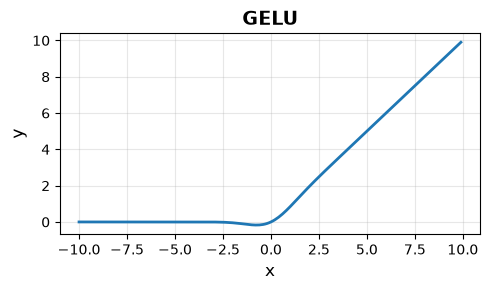

In [5]:
import matplotlib.pyplot as plt

gelu = GELU()

plt.figure(figsize=(5, 3))
x_range = np.arange(-10, 10, 0.1)
plt.plot(x_range, [gelu(Tensor(x)).data for x in x_range], linewidth=2)
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.title('GELU', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 损失函数

### GPT 交叉熵损失函数

RNN 模型是逐个词元进行计算，然后我们也是逐个计算交叉熵损失，然后再求和。

GPT 模型可以一次性计算样本的全部词元，输出多个预测值，格式为 `(批大小, 上下文尺寸, 词表大小)`。实践中，我们可以把预测值和标签值都拉平成一个大的 2 维向量，格式为 `(批大小 * 上下文尺寸, 词表大小)`，从而利用 NumPy 的向量化运算能力，一次性计算全部的交叉熵损失。

**GPTLoss** 就是交叉熵损失函数的**批处理**升级版。

In [6]:
class GPTLoss(Loss):

    def loss(self, p: Tensor, y: Tensor):
        exp = np.exp(p.data - np.max(p.data, axis=-1, keepdims=True))
        softmax = exp / np.sum(exp, axis=-1, keepdims=True)

        flat_softmax = softmax.reshape(-1, softmax.shape[-1])
        flat_y = y.data.reshape(-1).astype(np.int64)
        n = len(flat_y)
        rows = np.arange(n)

        log = np.log(np.clip(flat_softmax[rows, flat_y], 1e-10, 1))
        ce = Tensor(0 - np.sum(log) / n)

        def gradient_fn():
            flat_grad = flat_softmax.copy()
            flat_grad[rows, flat_y] -= 1
            p.grad += ce.grad * flat_grad.reshape(softmax.shape) / n

        return ce.attach(gradient_fn, parents={p})

## 模型

一个完整的 GPT 模型由三个模块组成：

* **Embedding**（嵌入层）：把输入文字的词元索引编码转换成词向量；
* **Transformer**（转换器模块）：多次循环，对词向量逐层提炼特征；
* **Output**（输出层）：把词向量映射成词表概率。

<div style="text-align: center;">
  <img src="images/token-embedding.png">
  <div>图例：GPT 基础模块</div>
</div>

### GPT 嵌入层

**GPT 嵌入层**（GPT Embedding Layer）是 GPT 模型的第一层，负责把整段文字的索引编码转换成稠密的**词向量**。

和 RNN 模型不同的是，不再使用**平均池化层**把整段文字的所有词向量合并成一个词袋向量，造成语序信息的丢失。GPT 模型将保留每个词元的词向量，维持语序信息贯穿整个模型。

In [7]:
class GPTEmbedding(Composite):

    def __init__(self, vocab_size, embedding_size):
        self.embedding = Embedding(vocab_size, embedding_size)

        super().__init__([self.embedding])

    def forward(self, x: Tensor):
        return self.embedding(x)

### GPT 前馈网络层

**GPT 前馈网络层**（GPT Feed Forward Network Layer，FFN Layer）就是一个标准的两层全连接网络模型：一个**线性隐藏层** + 一个**GELU激活函数** + 一个**线性输出层**。负责挖掘数据的内在逻辑。

``💡 前馈网络层的隐藏层将数据尺寸扩大 4 倍，然后在输出层再压缩回原来的尺寸，保持数据在层和层之间可以顺利衔接。这也是 GPT 模型的标准配置。``

In [8]:
class GPTFeedForward(Composite):

    def __init__(self, embedding_size):
        self.input = Linear(embedding_size, embedding_size * 4)
        self.gelu = GELU()
        self.output = Linear(embedding_size * 4, embedding_size)

        super().__init__([self.input,
                          self.gelu,
                          self.output])

    def forward(self, x: Tensor):
        h = self.gelu(self.input(x))
        return self.output(h)

### GPT 转换器模块

**GPT 转换器模块**（GPT Transformer Block）是 GPT模型的核心组件。目前只包括一个前馈网络层，后续我们将扩展注意力机制部分。

GPT 模型虽然可以一次性并行处理一个样本的所有词元，但是一次计算显然不能训练充分。所以会多次循环调用转换器模块，逐步提炼数据的内在逻辑。

In [9]:
class GPTTransformer(Composite):

    def __init__(self, embedding_size):
        self.feed_forward = GPTFeedForward(embedding_size)

        super().__init__([self.feed_forward])

    def forward(self, x: Tensor):
        return self.feed_forward(x)

### GPT 输出层

**GPT 输出层**（GPT Output Layer）的主体是一个线性层，负责把每个位置的词向量映射到词表大小的向量，和标签值对应。输出数值为**逻辑值**（Logits）。经过交叉熵损失函数中包含的 Softmax 激活函数转换后，最终每个数值代表对应词元的概率。

In [10]:
class GPTOutput(Composite):

    def __init__(self, embedding_size, vocab_size):
        self.output = Linear(embedding_size, vocab_size)

        super().__init__([self.output])

    def forward(self, x: Tensor):
        return self.output(x)

### GPT 模型

最后，我们把三个部分组装成完整的 GPT 模型，其中会包括若干个 Transformer 模块，对数据多次提炼特征。

数据在模型各个部分移动时，其格式也在变化：

$$
(\text{批}, \text{上下文}) \xrightarrow{\text{嵌入}} (\text{批}, \text{上下文}, \text{嵌入}) \xrightarrow{\text{转换器模块} \times n} (\text{批}, \text{上下文}, \text{嵌入}) \xrightarrow{\text{输出}} (\text{批}, \text{上下文}, \text{词表})
$$

可以看出，序列维度 `(批大小, 上下文尺寸)` 自始至终保持不变。每个位置独立地完成各自的预测，这正是 GPT 可以并行训练的关键。

In [11]:
class GPT(Composite):

    def __init__(self, vocab_size, embedding_size, blocks):
        self.embedding = GPTEmbedding(vocab_size, embedding_size)
        self.transformers = [GPTTransformer(embedding_size) for _ in range(blocks)]
        self.output = GPTOutput(embedding_size, vocab_size)

        super().__init__([self.embedding] + self.transformers + [self.output])

    def forward(self, x: Tensor):
        x = self.embedding(x)
        for layer in self.transformers:
            x = layer(x)
        return self.output(x)

## GPT 训练器

GPT 训练器和 RNN 训练器大同小异，有三个值得注意的区别：

* **损失计算**：不再需要逐个时间步循环，而是一次调用损失函数就可以完成所有位置的计算；
* **关闭梯度**：评估和文本生成时不需要生成计算图和反向传播。使用框架提供的函数 Tensor.no_grad 临时关闭梯度计算，节约内存和算力；
* **文本生成**：生成函数 generate 实现了 GPT 的**自回归生成**（Autoregressive Generation）：
    * 把提示词 prompt 编码成词元序列；
    * 每次取最后 `context_size` 个词元作为输入，运行模型；
    * 只取预测值最后一个位置的逻辑值，转换成概率分布，随机采样出下一个词元；
    * 把新词元追加到词元序列末尾，并重复上述过程。

``💡 生成文本时采用随机采样（Sampling）而不是直接取概率最大的词元，是为了让每次生成的内容有不同的表达，避免模型陷入重复。``


In [12]:
class GPTTrainer(Trainer):

    def train(self, dataset, epochs, scheduler=None):
        dataset.train()
        self.model.train()

        steps = 0
        for epoch in range(epochs):
            for i in range(len(dataset)):
                if scheduler is not None:
                    self.optimizer.lr = scheduler.step(steps)

                feature, label = dataset[i]

                self.optimizer.zero_grad()
                prediction = self.model(feature)
                loss = self.loss_fn(prediction, label)
                loss.backward()
                self.optimizer.clip_grad_norm()
                self.optimizer.step()
                steps += 1

    def test(self, dataset):
        dataset.eval()
        self.model.eval()

        predictions = []
        total_loss = 0.0
        with Tensor.no_grad():
            for i in range(len(dataset)):
                feature, label = dataset[i]
                prediction = self.model(feature)
                loss = self.loss_fn(prediction, label)
                predictions.append(prediction)
                total_loss += float(loss.data)

        loss = total_loss / len(dataset)
        dataset.train()
        self.model.train()
        return predictions, loss

    def generate(self, dataset, prompt, steps=256):
        self.model.eval()
        tokens = dataset.encode(prompt)

        with Tensor.no_grad():
            for _ in range(steps):
                feature = Tensor([tokens[-dataset.context_size:]])
                logits = self.model(feature)

                last_logits = logits.data[0, -1]
                exp = np.exp(last_logits - np.max(last_logits))
                probs = exp / np.sum(exp)
                token = np.random.choice(len(probs), p=probs)
                tokens.append(token)

        return dataset.decode(tokens)

## 超参数

### 学习率

In [13]:
LEARNING_RATE = 0.001

### 批大小

In [14]:
BATCH_SIZE = 4

### 轮数

In [15]:
EPOCHS = 2

### 上下文尺寸

In [16]:
CONTEXT_SIZE = 32

### 嵌入尺寸

In [17]:
EMBEDDING_SIZE = 64

### 转换器模块数

这是新的超参数，定义 GPT 模型中包括多少个 Transformer 转换器模块。

In [18]:
BLOCKS = 2

## 建模

In [19]:
DATA_FILE = "../../../../data/tinyshakespeare.txt"

dataset = CharDataset(DATA_FILE, BATCH_SIZE, CONTEXT_SIZE)
model = GPT(dataset.vocab_size, EMBEDDING_SIZE, BLOCKS)
loss_fn = GPTLoss()
optimizer = AdamWOptimizer(model.parameters, lr=LEARNING_RATE)
trainer = GPTTrainer(model, loss_fn, optimizer)

## 训练

In [20]:
scheduler = WarmupCosineScheduler(LEARNING_RATE, EPOCHS * len(dataset), 100, LEARNING_RATE / 10)
trainer.train(dataset, EPOCHS, scheduler)

## 评估

In [21]:
prediction, loss = trainer.test(dataset)
print(f'prediction:\t{len(prediction)} steps, each {prediction[0].data.shape}\nloss:\t{loss}')

prediction:	1742 steps, each (4, 32, 65)
loss:	2.4602363050736735


## 推理

In [22]:
print(trainer.generate(dataset, prompt="ROMEO:"))

ROMEO:
ABIO:
Prt gee wl d lore wesed.
Tr'
IO, ftids theshisin and yono avero s.
DUnd mer wn gack nome sthal nksel aichosd a d ast t, aif we bllyoobatis, thee, higherel llote he
Whiosofispenccche hee weldealvigis y winosouless prio, o whagsd lld sentte did st Lom


本章，我们搭建了 GPT 模型的基本骨架：

* **嵌入层**把文字变成向量；
* **转换器模块**提炼特征；
* **输出层**生成词表概率。

最后，通过**自回归生成**让模型开口讲话。

不过，目前的模型有两个明显的问题，使得输出结果和 RNN 模型相比，并没有明显提升：

* **没有位置信息**：每个词元的词向量只包含**它是什么**，不包含**它在哪里**。本质上和词袋模型没有区别；
* **没有上下文交流**：前馈网络是一个两层全连接神经网络，每个位置独立计算，词元之间互不影响，每个位置的预测只取决于自身。

后续章节，我们将继续扩展模型，着手解决这两个问题。

## 课后练习

GPT 模型采用多个 Transformer 模块串联的方式，来层层递进、提炼特征。试试调整转换器模块数 BLOCKS，观察训练速度和生成效果有什么变化？